In [4]:
import pandas as pd
import numpy as np

# loading the CSV files
train_images = pd.read_csv("D:\OneDrive\OneDrive\Desktop\AHD_P\csvTestImages 3360x1024.csv", header=None).values
train_labels = pd.read_csv("D:\OneDrive\OneDrive\Desktop\AHD_P\csvTestLabel 3360x1.csv", header=None).values

# print the shape of the loaded data for verification
print(f"Training images shape: {train_images.shape}")
print(f"Training labels shape: {train_labels.shape}")


Training images shape: (3360, 1024)
Training labels shape: (3360, 1)


In [5]:
# Reshape each image back to 32x32 (grayscale)
train_images = train_images.reshape(-1, 32, 32, 1)  # 32x32x1 (grayscale)

# Normalize the images to a range of 0 to 1
train_images = train_images / 255.0

# Print the shape and verify the normalization
print(f"Reshaped and normalized training images shape: {train_images.shape}")


Reshaped and normalized training images shape: (3360, 32, 32, 1)


In [6]:
from sklearn.model_selection import train_test_split

# spliting the data into training and validation sets (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(train_images, train_labels, test_size=0.2, random_state=42)

# Printing the shapes of the splits to confirm
print(f"Training images shape: {X_train.shape}")
print(f"Validation images shape: {X_val.shape}")


Training images shape: (2688, 32, 32, 1)
Validation images shape: (672, 32, 32, 1)


In [7]:
import tensorflow as tf
from tensorflow import keras
from keras import layers, models

# define the CNN model
model = models.Sequential([
    # First Convolutional layer with 32 filters, kernel size (3x3), ReLU activation
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 1)),
    layers.MaxPooling2D((2, 2)),  # Max pooling to reduce dimensionality

    # Second Convolutional layer with 64 filters, kernel size (3x3), ReLU activation
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),  # Max pooling to reduce dimensionality

    # Flatten the output from 2D to 1D for the fully connected layers
    layers.Flatten(),

    # Fully connected layer with 128 neurons and ReLU activation
    layers.Dense(128, activation='relu'),

    # Output layer with 28 neurons (one for each class) and softmax activation for multi-class classification
    layers.Dense(28, activation='softmax')  # 28 classes for Arabic handwritten characters
])

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Print the model summary to see the architecture
model.summary()


d:\Downloades\Anaconda\envs\Alan\lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 28)             │         3,612 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 317,468 (1.21 MB)

 Trainable params: 317,468 (1.21 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
import numpy as np

# Make labels 1D and int
y_train = y_train.squeeze().astype("int32")
y_val   = y_val.squeeze().astype("int32")

print(y_train.shape, y_val.shape, y_train[:10])


(2688,) (672,) [ 4  6  3 17 11 21 13 27  2 13]


In [12]:
history = model.fit(
    X_train, y_train,
    epochs=15,          # you can change later (10–20 is typical)
    batch_size=64,
    validation_data=(X_val, y_val)
)


Epoch 1/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.1170 - loss: 3.1693 - val_accuracy: 0.3095 - val_loss: 2.4064
Epoch 2/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.3552 - loss: 2.1741 - val_accuracy: 0.4702 - val_loss: 1.7867
Epoch 3/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.4859 - loss: 1.6426 - val_accuracy: 0.5595 - val_loss: 1.3945
Epoch 4/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6454 - loss: 1.1678 - val_accuracy: 0.6101 - val_loss: 1.1772
Epoch 5/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7223 - loss: 0.8560 - val_accuracy: 0.6756 - val_loss: 1.0178
Epoch 6/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8047 - loss: 0.6383 - val_accuracy: 0.7307 - val_loss: 0.8554
Epoch 7/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8413 - loss: 0.5168 - val_accuracy: 0.7336 - val_loss: 0.8838
Epoch 8/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8889 - loss: 0.3907 - val_accuracy: 0.7500 - v

In [13]:
val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")


Validation loss: 0.7773
Validation accuracy: 0.8021


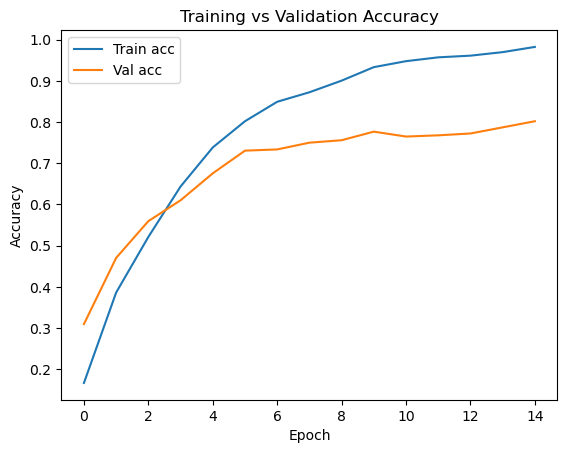

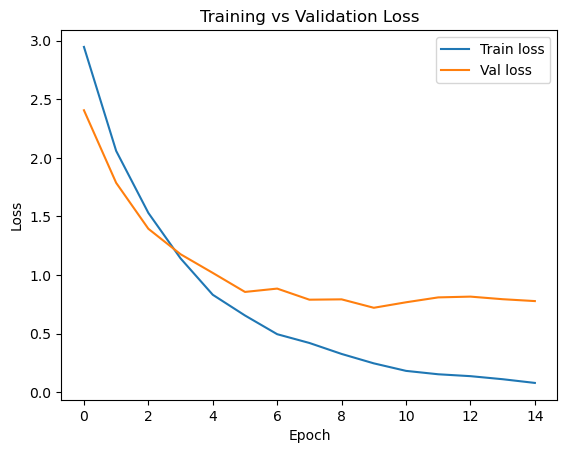

In [14]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure()
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training vs Validation Accuracy')
plt.show()

# Loss
plt.figure()
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training vs Validation Loss')
plt.show()


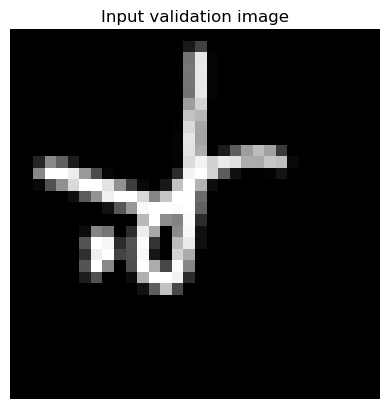

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Predicted class (0–27): 16
True class (0–27):      16


In [18]:
import numpy as np

idx = 11 
image = X_val[idx]

plt.imshow(image.squeeze(), cmap='gray')
plt.title("Input validation image")
plt.axis('off')
plt.show()

pred = model.predict(image[np.newaxis, ...])
predicted_class = np.argmax(pred)

print("Predicted class (0–27):", predicted_class)
print("True class (0–27):     ", y_val[idx])


In [19]:
arabic_letters = [
    "ا","ب","ت","ث","ج","ح","خ","د","ذ","ر","ز","س","ش","ص",
    "ض","ط","ظ","ع","غ","ف","ق","ك","ل","م","ن","ه","و","ي"
]


In [20]:
def test_prediction(index):
    image = X_val[index]

    # Show image
    plt.imshow(image.squeeze(), cmap='gray')
    plt.title("Input validation image")
    plt.axis('off')
    plt.show()

    # Predict
    pred = model.predict(image[np.newaxis, ...])
    
    pred_idx = np.argmax(pred)
    true_idx = y_val[index]

    print("Predicted class index:", pred_idx, "→", arabic_letters[pred_idx])
    print("True class index:     ", true_idx, "→", arabic_letters[true_idx])


Testing sample index: 73


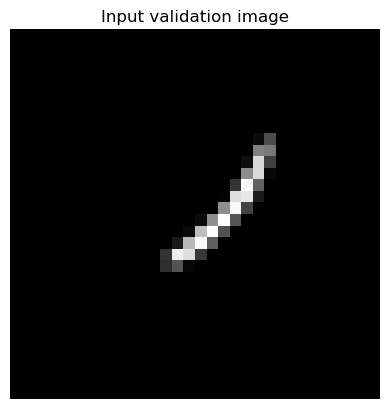

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Predicted class index: 9 → ر
True class index:      9 → ر
Testing sample index: 193


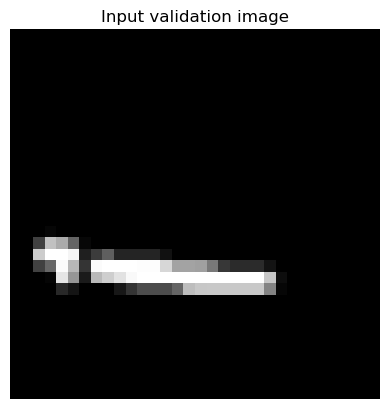

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Predicted class index: 0 → ا
True class index:      0 → ا
Testing sample index: 432


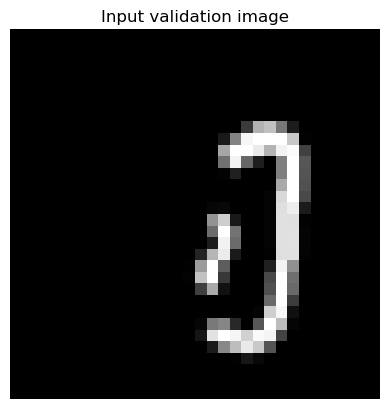

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Predicted class index: 3 → ث
True class index:      2 → ت
Testing sample index: 165


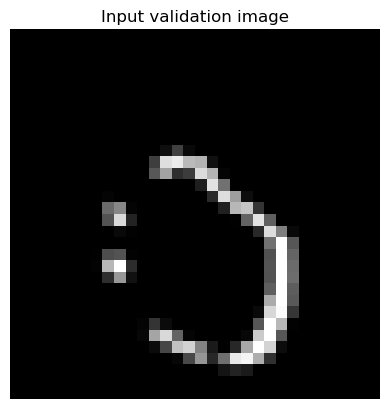

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Predicted class index: 2 → ت
True class index:      2 → ت
Testing sample index: 658


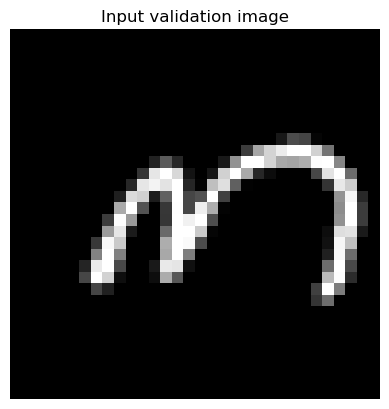

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Predicted class index: 17 → ع
True class index:      17 → ع


In [21]:
import random

for _ in range(5):
    idx = random.randint(0, len(X_val)-1)
    print("="*40)
    print("Testing sample index:", idx)
    test_prediction(idx)


In [22]:
from keras.models import save_model  # optional, model.save also works

model.save("arabic_handwriting_cnn.h5")
print("arabic_handwriting_cnn.h5 Model saved")


arabic_handwriting_cnn.h5 Model saved


In [10]:
import numpy as np

print("Train labels unique:", np.unique(y_train)[:30])
print("Val labels unique:", np.unique(y_val)[:30])


Train labels unique: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28]
Val labels unique: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28]


In [11]:
# Make labels 0–27 instead of 1–28
y_train = (y_train.squeeze().astype("int32")) - 1
y_val   = (y_val.squeeze().astype("int32")) - 1

print("Train labels unique AFTER shift:", np.unique(y_train))
print("Val labels unique AFTER shift:", np.unique(y_val))


Train labels unique AFTER shift: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27]
Val labels unique AFTER shift: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27]
